# Price elasticity and markdown optimization: walkthrough

Same pipeline as `src/`, with the intermediate tables shown. Run `run_all.sh` first.

In [1]:
import os, sys, json
sys.path.insert(0, os.path.abspath('..'))
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

panel = pd.read_parquet('../data/weekly.parquet')
products = pd.read_csv('../results/products.csv', dtype={'sku': str})
print(f'{len(panel):,} product-weeks, {len(products)} products')
products.head(8)

5,622 product-weeks, 60 products


,sku,weeks,revenue,price_levels,description
0,85099B,104,166871.27,5,JUMBO BAG RED RETROSPOT
1,47566,103,140266.70,6,PARTY BUNTING
2,22086,83,120037.49,12,PAPER CHAIN KIT 50'S CHRISTMAS
3,79321,97,84382.01,7,CHILLI LIGHTS
4,22197,104,76017.09,5,SMALL POPCORN HOLDER
5,84347,75,71748.17,9,ROTATING SILVER ANGELS T-LIGHT HLDR
6,22386,97,69355.62,5,JUMBO BAG PINK POLKADOT
7,21137,99,67546.90,5,BLACK RECORD COVER FRAME


## 1. One product's weekly price and units

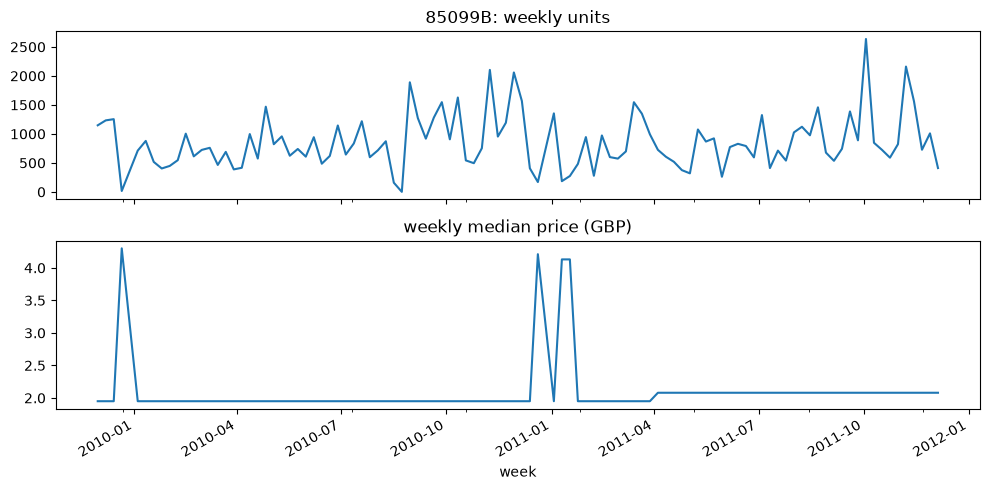

In [2]:
sku = products['sku'].iloc[0]
g = panel[panel['sku'] == sku].set_index('week')
fig, ax = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
g['units'].plot(ax=ax[0], title=f'{sku}: weekly units'); g['median_price'].plot(ax=ax[1], title='weekly median price (GBP)')
plt.tight_layout(); plt.show()

## 2. Elasticities

In [3]:
el = pd.read_csv('../results/elasticities.csv', dtype={'sku': str})
print(f"usable: {el['usable'].sum()} of {len(el)}; median elasticity {el.loc[el['usable'], 'elasticity'].median():.2f}")
el.sort_values('r2', ascending=False)[['sku', 'description', 'elasticity', 'se', 'p_value', 'r2', 'weeks', 'usable']].head(10)

usable: 45 of 60; median elasticity -2.30


,sku,description,elasticity,se,p_value,r2,weeks,usable
12,22910,PAPER CHAIN KIT VINTAGE CHRISTMAS,-3.178262,0.652416,1.107380e-06,0.930036,50,True
54,22835,HOT WATER BOTTLE I AM SO POORLY,-0.795352,0.571900,1.643105e-01,0.830634,64,False
2,22086,PAPER CHAIN KIT 50'S CHRISTMAS,-2.042182,0.522033,9.154414e-05,0.822525,83,True
26,84029E,RED WOOLLY HOTTIE WHITE HEART.,-2.602482,0.531093,9.571907e-07,0.821474,95,True
41,21479,WHITE SKULL HOT WATER BOTTLE,0.983933,0.824427,2.326832e-01,0.821252,57,False
40,21485,RETROSPOT HEART HOT WATER BOTTLE,-1.766914,0.491361,3.231984e-04,0.813787,99,True
45,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,-0.698881,0.352151,4.718854e-02,0.783226,101,True
5,84347,ROTATING SILVER ANGELS T-LIGHT HLDR,-2.110922,0.913100,2.078763e-02,0.781406,75,True
23,22111,SCOTTIE DOG HOT WATER BOTTLE,-1.444756,0.551300,8.776581e-03,0.778180,100,True
14,22112,CHOCOLATE HOT WATER BOTTLE,-1.269196,0.359003,4.072523e-04,0.771131,104,True


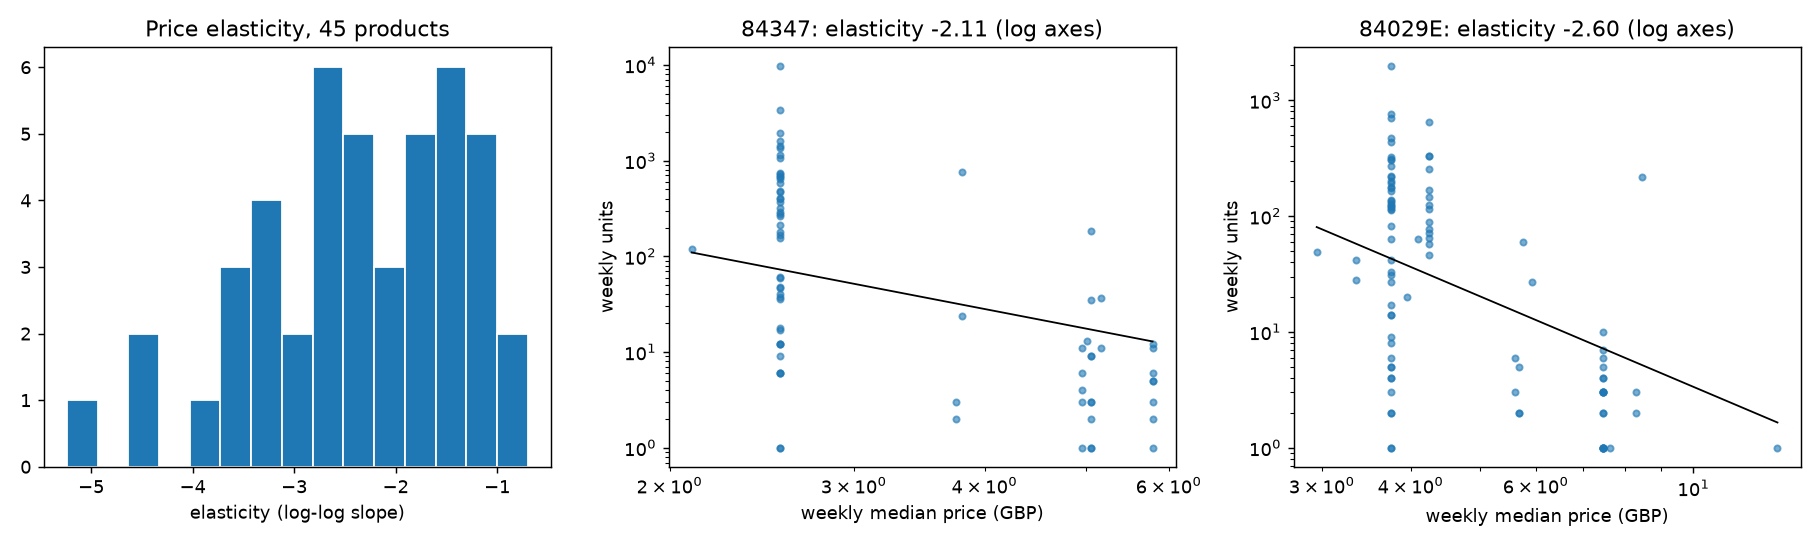

In [4]:
display(Image('../results/elasticities.png', width=950))

## 3. Markdown scenarios

In [5]:
scen = pd.read_csv('../results/scenarios.csv')
scen

,scenario,revenue,margin,units,discount_cost,products_marked_down,avg_depth
0,no_markdown,128853.0,57984.0,42746.0,0.0,0,0.000
1,max_revenue,149342.0,55099.0,56981.0,22008.0,40,0.129
2,revenue_margin,147696.0,57993.0,53728.0,15401.0,32,0.082
3,max_margin,141193.0,59671.0,49019.0,7028.0,18,0.040
4,budget_capped,146303.0,58749.0,52592.0,12885.0,29,0.069


In [6]:
plan = pd.read_csv('../results/markdown_plan.csv', dtype={'sku': str})
print(plan['depth'].value_counts().sort_index().rename('products per depth'))
plan.head(10)

depth
0.0    13
0.1    27
0.2     5
Name: products per depth, dtype: int64


,sku,description,list_price,elasticity,depth,price,units,revenue,margin
0,22086,PAPER CHAIN KIT 50'S CHRISTMAS,2.95,-2.04,0.1,2.66,5768.79,15316.14,5956.28
1,85099B,JUMBO BAG RED RETROSPOT,2.08,-2.63,0.1,1.87,6050.88,11327.25,4405.04
2,22910,PAPER CHAIN KIT VINTAGE CHRISTMAS,2.95,-3.18,0.1,2.66,3383.02,8981.92,3492.97
3,79321,CHILLI LIGHTS,5.75,-3.38,0.1,5.18,1668.29,8633.39,3357.43
4,22114,HOT WATER BOTTLE TEA AND SYMPATHY,4.25,-1.80,0.2,3.40,1946.97,6619.68,2068.65
5,84347,ROTATING SILVER ANGELS T-LIGHT HLDR,2.55,-2.11,0.1,2.30,2534.38,5816.41,2261.94
6,21137,BLACK RECORD COVER FRAME,3.75,-4.35,0.0,3.75,1542.33,5783.75,2602.69
7,22112,CHOCOLATE HOT WATER BOTTLE,4.95,-1.27,0.0,4.95,1045.00,5172.75,2327.74
8,22386,JUMBO BAG PINK POLKADOT,2.08,-1.68,0.2,1.66,2926.52,4869.73,1521.79
9,22178,VICTORIAN GLASS HANGING T-LIGHT,1.95,-2.30,0.1,1.76,2736.71,4802.92,1867.80


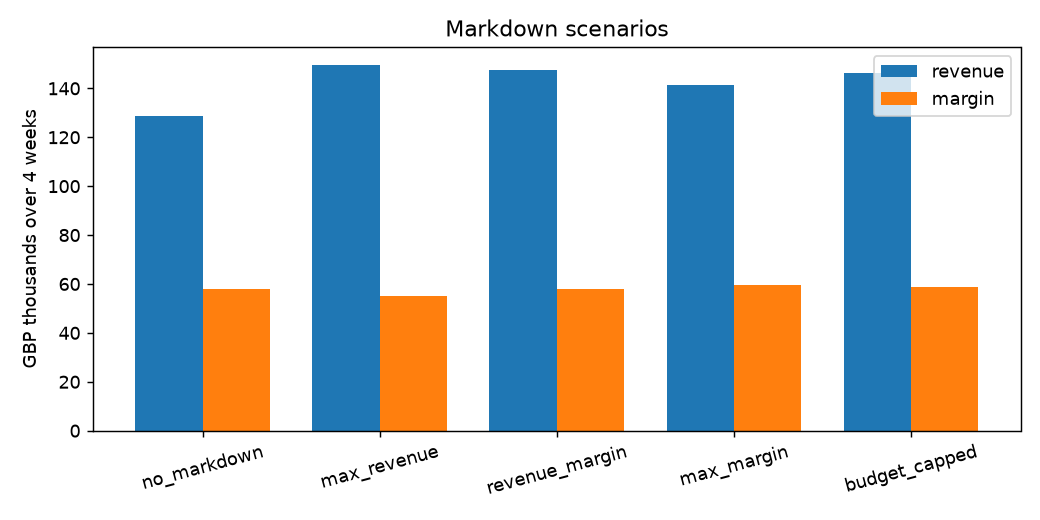

In [7]:
display(Image('../results/scenarios.png', width=640))

Revenue-only optimization discounts nearly everything; the margin floor keeps margin whole while still lifting revenue, and the inventory cap binds on the most elastic products. The cost, inventory and budget assumptions are parameters in `src/optimize.py`; change them and rerun to see how the plan moves.